# 15. Under the Hood

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In this chapter we “open the hood,” looking more closely at how some of the tools we have used—`ode45`, `fzero`, and `fminsearch`—work.

## How ode45 Works

According to the MATLAB documentation, `ode45` uses “an explicit Runge-Kutta formula, the Dormand-Prince pair.” You can read about it at <https://greenteapress.com/matlab/runge>, but I’ll give you a sense of it here.

The key idea behind all Runge-Kutta methods is to evaluate the rate function several times at each time step and use a weighted average of the computed slopes to estimate the value at the next time step. Different methods evaluate the rate function in different places and compute the average with different weights.

As an example, we’ll solve the following differential equation:

$$\frac{dy}{dt}(t) = y \sin t$$

Given a differential equation, it’s usually straightforward to write a rate function:

In [2]:
function res = rate_func(t, y)
    dydt = y * sin(t);
    res = dydt;
end

And we can use it like this:

In [3]:
y0 = 1;
tspan=[0 4];
options = odeset('Refine', 1);
[T, Y] = ode45(@rate_func, tspan, y0, options);

For this example we’ll use `odeset` to set the `Refine` option to `1`, which tells `ode45` to return only the time steps it computes, rather than interpolating between them.

Now we can modify the rate function to plot the places where it gets evaluated:

In [4]:
function res = rate_func(t, y)
    dydt = y * sin(t);
    res = dydt;

    plot(t, y, 'ro')
    dt = 0.01;
    ts = [t t+dt];
    ys = [y y+dydt*dt];
    plot(ts, ys, 'r-')
end

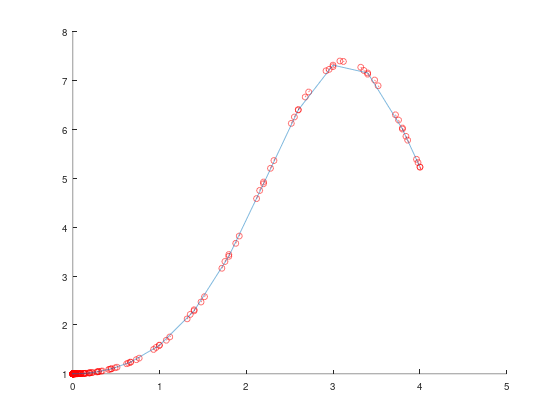

In [5]:
% Run ode45 again with the new rate function (Figure 15.1)
hold on
[T, Y] = ode45(@rate_func, tspan, y0, options);
plot(T, Y, '-')

*In Octave, `ode45` takes more, smaller steps than in MATLAB (29 time steps and 177 evaluations of the rate function here), so the plot has more points than Figure 15.1.*

When `rate_func` runs, it plots a red circle at each location and a short red line showing the computed slope.

Figure 15.1 shows the result; `ode45` computes 10 time steps (not counting the initial condition) and evaluates the rate function 61 times.

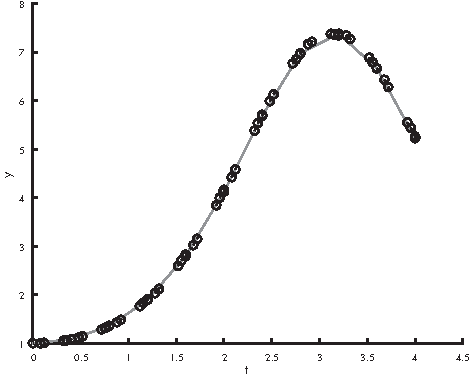

*Figure 15.1: Points where `ode45` evaluates the rate function*

Figure 15.2 shows the same plot, zoomed in on a single time step. The dark squares at $0.8$ to $1.2$ show the values that were returned as part of the solution. The circles show the places where the rate function was evaluated.

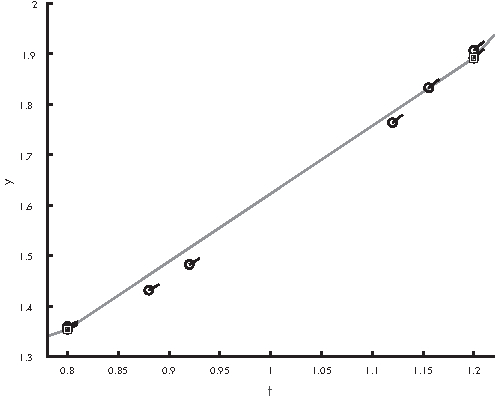

*Figure 15.2: Points where `ode45` evaluates the rate function, zoomed in*

We can see that `ode45` evaluates the rate function several times per time step, at several places between the end points. We can also see that most of the places where `ode45` evaluates the rate function are not part of the solution it returns, and they are not always good estimates of the solution. This is good to know when you are writing a rate function; you should not assume that the time and state you get as input variables will be part of the solution.

In a sense, the rate function is answering a hypothetical question: “*If* the state at a particular time has these particular values, what *would* the slope be?”

At each time step, `ode45` actually computes *two* estimates of the next value. By comparing them, it can estimate the magnitude of the error, which it uses to adjust the time step. If the error is too big, it uses a smaller time step; if the error is small enough, it uses a bigger time step. Because `ode45` is *adaptive* in this way, it minimizes the number of times it calls the rate function to achieve a given level of accuracy.

## How fzero Works

According to the MATLAB documentation, `fzero` uses “a combination of bisection, secant, and inverse quadratic interpolation methods.” (See <https://greenteapress.com/matlab/fzero>)

To understand what that means, suppose we’re trying to find a root of a function of one variable, $f(x)$, and assume we have evaluated the function at two places, $x_1$ and $x_2$, and found that the results have opposite signs. Specifically, assume $f(x_1) > 0$ and $f(x_2) < 0$, as shown in Figure 15.3.

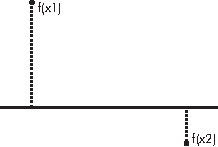

*Figure 15.3: Initial state of a root-finding search*

As long as $f$ is continuous, there must be at least one root in this interval. In this case we would say that $x_1$ and $x_2$ *bracket* a zero.

If this were all you knew about $f$, where would you go looking for a root? If you said “halfway between $x_1$ and $x_2$,” congratulations! You just invented a numerical method called *bisection*!

If you said, “I would connect the dots with a straight line and compute the zero of the line,” congratulations! You just invented the *secant method*!

And if you said, “I would evaluate $f$ at a third point, find the parabola that passes through all three points, and compute the zeros of the parabola,” congratulations, you just invented *inverse quadratic interpolation*!

That’s most of how `fzero` works. The details of how these methods are combined are interesting, but beyond the scope of this book. You can read more at <https://greenteapress.com/matlab/brent>.

## How fminsearch Works

According to the MATLAB documentation, `fminsearch` uses the Nelder-Mead simplex algorithm. You can read about it at <https://greenteapress.com/matlab/nelder>, but you might find it overwhelming.

To give you a sense of how it works, I will present a simpler algorithm, the *golden-section search*. Suppose we’re trying to find the minimum of a function of a single variable, $f(x)$.

As a starting place, assume that we have evaluated the function at three places, $x_1$, $x_2$, and $x_3$, and found that $x_2$ yields the lowest value. Figure 15.4 shows this initial state.

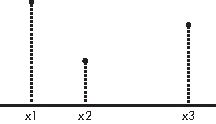

*Figure 15.4: Initial state of a golden-section search*

We will assume that $f(x)$ is continuous and *unimodal* in this range, which means that there is exactly one minimum between $x_1$ and $x_3$.

The next step is to choose a fourth point, $x_4$, and evaluate $f(x_4)$. There are two possible outcomes, depending on whether $f(x_4)$ is greater than $f(x_2)$ or not. Figure 15.5 shows the two possible states.

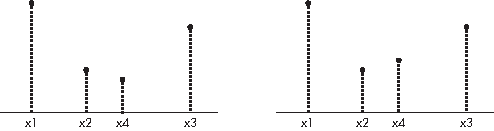

*Figure 15.5: Possible states of a golden-section search after evaluating $f(x_4)$*

If $f(x_4)$ is less than $f(x_2)$ (shown on the left), the minimum must be between $x_2$ and $x_3$, so we would discard $x_1$ and proceed with the new triple $(x_2, x_4, x_3)$.

If $f(x_4)$ is greater than $f(x_2)$ (shown on the right), the local minimum must be between $x_1$ and $x_4$, so we would discard $x_3$ and proceed with the new triple $(x_1, x_2, x_4)$.

Either way, the range gets smaller and our estimate of the optimal value of $x$ gets better.

This method works for almost any value of $x_4$, but some choices are better than others. You might be tempted to bisect the interval between $x_2$ and $x_3$, but that turns out not to be the best choice. You can read about a better option at <https://greenteapress.com/matlab/golden>.

## Chapter Review

The information in this chapter is not strictly necessary; you can use these methods without knowing much about how they work. But there are two reasons you might want to know.

One reason is pure curiosity. If you use these methods, and especially if you come to rely on them, you might find it unsatisfying to treat them as “black boxes.” At the risk of mixing metaphors, I hope you enjoyed opening the hood.

The other reason is that these methods are not infallible; sometimes things go wrong. If you know how they work, at least in a general sense, you might find it easier to debug them.

With that, you have reached the end of the book, so congratulations! I hope you enjoyed it and learned a lot. I think the tools in this book are useful, and the ways of thinking are important, not just in engineering and science, but in practically every field of inquiry.

Models are the tools we use to understand the world: if you build good models, you are more likely to get things right. Good luck!